In [ ]:
import pandas as pd

# 1. Load the dataset
a = pd.read_csv("/content/sample_data/california_housing_test.csv")

# 2. Display first 5 rows
print("First 5 rows of dataset:")
print(a.head())

# 3. Calculate Q1 (25th percentile)
q1 = a.quantile(0.25, numeric_only=True)

# 4. Calculate Q3 (75th percentile)
q2 = a.quantile(0.75, numeric_only=True)

# 5. Calculate IQR
iqr = q2 - q1

# 6. Calculate lower bound
b = q1 - (iqr * 1.5)

# 7. Calculate upper bound
c = q2 + (iqr * 1.5)

# 8. Display results
print("\nQ1 (25th Percentile):")
print(q1)

print("\nQ3 (75th Percentile):")
print(q2)

print("\nIQR:")
print(iqr)

print("\nLower Bound:")
print(b)

print("\nUpper Bound:")
print(c)

# 9. Detect outliers
outliers = ((a < b) | (a > c))

print("\nOutlier Count for Each Column:")
print(outliers.sum())

# 10. Remove outliers
a_clean = a[~outliers.any(axis=1)]

# 11. Display dataset size before and after removing outliers
print("\nOriginal Dataset Shape:")
print(a.shape)

print("\nDataset Shape After Removing Outliers:")
print(a_clean.shape)

# 12. Display cleaned dataset
print("\nCleaned Dataset:")
print(a_clean.head())


First 5 rows of dataset:
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.05     37.37                27.0       3885.0           661.0   
1    -118.30     34.26                43.0       1510.0           310.0   
2    -117.81     33.78                27.0       3589.0           507.0   
3    -118.36     33.82                28.0         67.0            15.0   
4    -119.67     36.33                19.0       1241.0           244.0   

   population  households  median_income  median_house_value  
0      1537.0       606.0         6.6085            344700.0  
1       809.0       277.0         3.5990            176500.0  
2      1484.0       495.0         5.7934            270500.0  
3        49.0        11.0         6.1359            330000.0  
4       850.0       237.0         2.9375             81700.0  

Q1 (25th Percentile):
longitude               -121.810
latitude                  33.930
housing_median_age        18.000
total_rooms             

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -114.31     34.19                15.0       5612.0          1283.0   
1    -114.47     34.40                19.0       7650.0          1901.0   
2    -114.56     33.69                17.0        720.0           174.0   
3    -114.57     33.64                14.0       1501.0           337.0   
4    -114.57     33.57                20.0       1454.0           326.0   

   population  households  median_income  median_house_value  
0      1015.0       472.0         1.4936             66900.0  
1      1129.0       463.0         1.8200             80100.0  
2       333.0       117.0         1.6509             85700.0  
3       515.0       226.0         3.1917             73400.0  
4       624.0       262.0         1.9250             65500.0  
Coefficient: 41669.9355465199
Intercept: 45238.285506641725

Actual vs Predicted:
     Actual      Predicted
0  142700.0  195079.206738
1  500001.0  383281.470634
2   6180

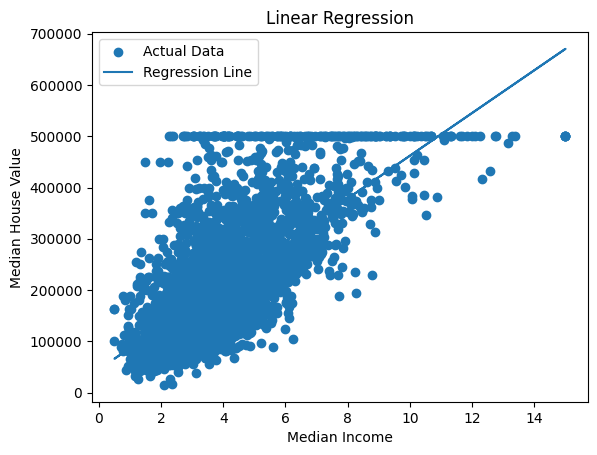

In [ ]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Load dataset
data = pd.read_csv("/content/sample_data/california_housing_train.csv")

# Display first 5 rows
print(data.head())

# Select input and output
# median_income -> independent variable (X)
# median_house_value -> dependent variable (y)
X = data[["median_income"]]
y = data["median_house_value"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Predict values
y_pred = model.predict(X_test)

# Display coefficient and intercept
print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

# Display predictions
print("\nActual vs Predicted:")
print(pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
}).head(10))

# Plot actual data
plt.scatter(X_test, y_test, label="Actual Data")

# Plot regression line
plt.plot(X_test, y_pred, label="Regression Line")

# Add labels and title
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Linear Regression")

plt.legend()
plt.show()

Intercept: -3652253.1348448903
Coefficients:
longitude: -43465.24768708999
latitude: -43106.30444149362
housing_median_age: 1131.724381984632
total_rooms: -8.84326062404216
total_bedrooms: 113.70797344414405
population: -35.65707687404938
households: 45.1475549553852
median_income: 40194.72634671582


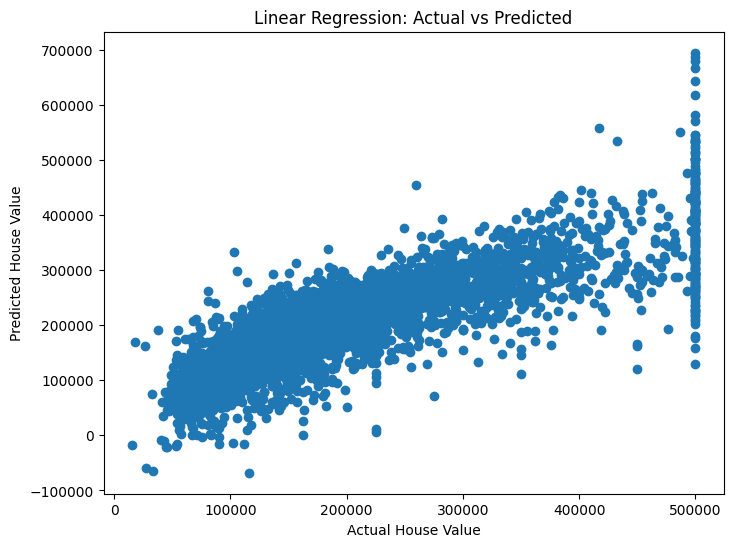

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Load dataset
df = pd.read_csv("/content/sample_data/california_housing_train.csv")

# Using iloc
X = df.iloc[:, :-1]      # All columns except last
y = df.iloc[:, -1]       # Last column (median_house_value)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train model
model = LinearRegression()
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Print model parameters
print("Intercept:", model.intercept_)
print("Coefficients:")
for col, coef in zip(X.columns, model.coef_):
    print(f"{col}: {coef}")

# Scatter plot (Actual vs Predicted)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

In [ ]:
import pandas as pd

# Load dataset
df = pd.read_csv("/content/sample_data/california_housing_train.csv")

# Display first 5 rows
print(df.head())

# Features (all columns except the last one)
X = df.iloc[:, :-1]

# Target (last column)
y = df.iloc[:, -1]

print("\nFeatures (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -114.31     34.19                15.0       5612.0          1283.0   
1    -114.47     34.40                19.0       7650.0          1901.0   
2    -114.56     33.69                17.0        720.0           174.0   
3    -114.57     33.64                14.0       1501.0           337.0   
4    -114.57     33.57                20.0       1454.0           326.0   

   population  households  median_income  median_house_value  
0      1015.0       472.0         1.4936             66900.0  
1      1129.0       463.0         1.8200             80100.0  
2       333.0       117.0         1.6509             85700.0  
3       515.0       226.0         3.1917             73400.0  
4       624.0       262.0         1.9250             65500.0  

Features (X):
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -114.31     34.19                15.0       5612.0          1283.0   
1    -